In [55]:
import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import gridspec
import matplotlib
plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

In [28]:


if torch.cuda.is_available():
    device = 'cuda'
else:
    device = 'cpu'

class Net(torch.nn.Module):
    def __init__(self, n, alpha=.2, sigma_rec=0., beta=10):
        super(Net, self).__init__()
        self.alpha = torch.tensor(alpha)
        self.sigma_rec = torch.tensor(sigma_rec)
        self.n = n
        self.beta = beta
        self.activation = torch.nn.Softplus(beta=self.beta)
        # self.activation = torch.nn.ReLU()

        # Connectivity
        self.recurrent_layer = nn.Linear(self.n, self.n, bias=True)
        self.recurrent_layer.bias.data.normal_(mean=0.2, std=0).to(device=device)
        self.recurrent_layer.bias.requires_grad = True

    # Dynamics
    def forward(self, steps, batch_size):

        states = torch.zeros(batch_size, 1, self.n, device=device)
        recurrent_noise = self.sigma_rec * torch.empty(batch_size, steps, self.n).normal_(
            mean=0,std=1).to(device=device)
        for i in range(steps - 1):
            state_new = (1 - self.alpha) * states[:, i, :] + self.alpha * (
                self.activation(self.recurrent_layer(states[:, i, :]) ) + states[:,i,:] * recurrent_noise[:,i,:])
            states = torch.cat((states, state_new.unsqueeze_(1)), 1)

        return states


    def fit(self, steps=100, batch_size=100, epochs=10000, lr=.01, verbose=True, weight_decay=0):



        optimizer = torch.optim.Adam(self.parameters(), lr=lr, weight_decay=weight_decay)
        epoch = 0
        # mse_z=1
        # lds = LDS(n=dim, hidden_n = 5).to(device)

        while epoch < epochs:

            optimizer.zero_grad()

            # Z-score batch data
            x_batch = self.forward(steps,batch_size)
            x_batch_centered = (x_batch - torch.mean(x_batch, dim=[0, 1])) / (torch.std(x_batch, dim=[0, 1]) + 1e-4)


            # PCA
            eigs = torch.sort(torch.real(
                torch.linalg.eigvals(torch.cov(x_batch_centered.reshape(-1, x_batch_centered.shape[2]).t()))),
                              descending=True)[0]

            loss = torch.sum(eigs[0]) / torch.sum(eigs)
            loss.backward()
            optimizer.step()
            self.recurrent_layer.bias.data = torch.nn.ReLU()(self.recurrent_layer.bias.data)
            epoch += 1
            if verbose:
                if epoch % 10 == 0:

                    print('Epoch: {}/{}.............'.format(epoch, epochs), end=' ')
                    print("pca: {:.4f}".format(loss.item()))
                # print("lds: {:.4f}".format(self.linear_error(linear_prediction,x_batch).item()))


In [43]:
rnn = Net(n = 50,sigma_rec = 0)

In [44]:
rnn.fit()

Epoch: 10/10000............. pca: 0.5185
Epoch: 20/10000............. pca: 0.4090
Epoch: 30/10000............. pca: 0.3459
Epoch: 40/10000............. pca: 0.3468
Epoch: 50/10000............. pca: 0.3146
Epoch: 60/10000............. pca: 0.3047
Epoch: 70/10000............. pca: 0.2860
Epoch: 80/10000............. pca: 0.3019
Epoch: 90/10000............. pca: 0.2562
Epoch: 100/10000............. pca: 0.2473


KeyboardInterrupt: 

In [135]:
rnn.sigma_rec=  .1
x = rnn(100,3000).detach()

In [136]:
rows = []
neuron = 0

for trial in range(x.shape[0]):
    for t in range(x.shape[1]):
        rows.append({'trial':trial,
                     't':t,
                     'x':x[trial,t,neuron].item(),}
        )
df = pd.DataFrame(rows)

Text(0, 0.5, 'Firing rate')

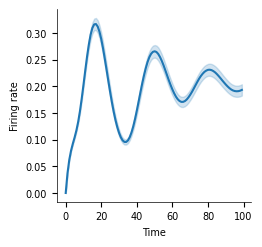

In [137]:

fig = plt.figure(figsize=(2.5,2.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.lineplot(data =df,x = 't', y = 'x',ax=ax,errorbar='sd')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.xaxis.set_tick_params(labelsize=7, bottom=True)
ax.yaxis.set_tick_params(labelsize=7, left=True)
ax.set_xlabel("Time",fontsize=7)
ax.set_ylabel("Firing rate",fontsize=7)

Text(0, 0.5, '$y_{t+1}-y_t$')

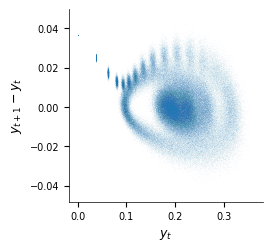

In [140]:
# Calculate snr at each t.
t= 60
h = torch.diff(x[:,:,neuron], dim = 1).flatten()
#h = x[:,t+20,neuron] - x[:,t,neuron]
z = x[:,:-1,neuron].flatten()

fig = plt.figure(figsize=(2.5,2.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.scatterplot(x = z, y = h,ax=ax,alpha = .05, s=.2)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.xaxis.set_tick_params(labelsize=7, bottom=True)
ax.yaxis.set_tick_params(labelsize=7, left=True)
ax.set_xlabel(r"$y_t$",fontsize=9)
ax.set_ylabel(r"$y_{t+1}-y_t$",fontsize=9)

Text(0, 0.5, '$f(h)$')

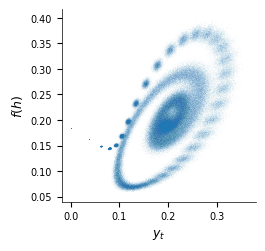

In [143]:
h = rnn.activation(rnn.recurrent_layer(x))[:,:,neuron].detach().flatten()
#h = torch.diff(x[:,:,neuron], dim = 1).flatten()
#h = x[:,t+20,neuron] - x[:,t,neuron]
z = x[:,:,neuron].flatten()

fig = plt.figure(figsize=(2.5,2.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.scatterplot(x = z, y = h,ax=ax,alpha = .05, s=.2)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.xaxis.set_tick_params(labelsize=7, bottom=True)
ax.yaxis.set_tick_params(labelsize=7, left=True)
ax.set_xlabel(r"$y_t$",fontsize=9)
ax.set_ylabel(r"$f(h)$",fontsize=9)

Text(0.5, 1.0, '0.6272803153502894')

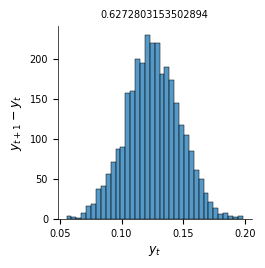

In [165]:
# Calculate snr at each t.
t= 5

h =( x[:,t+1,neuron] - x[:,t,neuron] ) / x[:,t,neuron]
#h = x[:,t+20,neuron] - x[:,t,neuron]
#z = x[:,:-1,neuron].flatten()

fig = plt.figure(figsize=(2.5,2.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.histplot(x = h,ax=ax)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.xaxis.set_tick_params(labelsize=7, bottom=True)
ax.yaxis.set_tick_params(labelsize=7, left=True)
ax.set_xlabel(r"$y_t$",fontsize=9)
ax.set_ylabel(r"$y_{t+1}-y_t$",fontsize=9)
ax.set_title(str(torch.mean(h).item()/rnn.alpha.item()),fontsize=7)

In [177]:
means = []
for t in range(99):
    h =( x[:,t+1,neuron] - x[:,t,neuron] ) / x[:,t,neuron]
    means.append(torch.std(h))

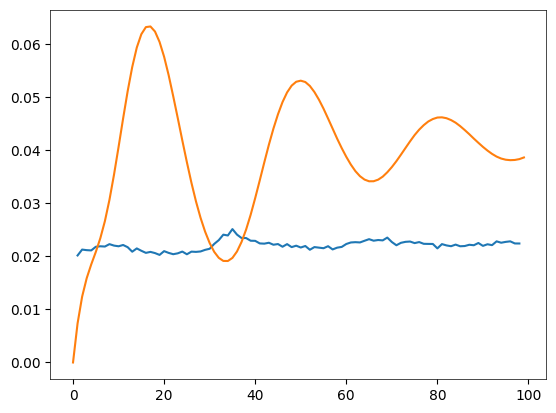

In [180]:
plt.figure()
plt.plot(means)
plt.plot(0.2*torch.mean(x[:,:,neuron],dim = 0))

In [174]:
rnn.alpha

tensor(0.2000)